# **Preliminary Data Analysis P2**

### Import data

In [ ]:
# importer les data, je prends que le body pas title
import pandas as pd

df = pd.read_csv(
    "../data/soc-redditHyperlinks-body.tsv",
    sep="\t"
)

print(df.shape)
display(df.head())

(286561, 6)


,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,PROPERTIES
0,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,"345.0,298.0,0.75652173913,0.0173913043478,0.08..."
1,theredlion,soccer,1u4qkd,2013-12-31 18:18:37,-1,"101.0,98.0,0.742574257426,0.019801980198,0.049..."
2,inlandempire,bikela,1u4qlzs,2014-01-01 14:54:35,1,"85.0,85.0,0.752941176471,0.0235294117647,0.082..."
3,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,"1124.0,949.0,0.772241992883,0.0017793594306,0...."
4,playmygame,gamedev,1u4w5ss,2014-01-01 02:51:13,1,"715.0,622.0,0.777622377622,0.00699300699301,0...."


### Basic statistics

In [ ]:
import pandas as pd

all_subreddits = pd.concat([
    df["SOURCE_SUBREDDIT"],
    df["TARGET_SUBREDDIT"]
])

#unique subreddits
n_subreddits = all_subreddits.nunique()

print("Total number of unique subreddits:", n_subreddits)

Total number of unique subreddits: 35776


In [ ]:
# on prend que les liens négatifs (LINK_SENTIMENT = -1)
negative = df[df["LINK_SENTIMENT"] == -1].copy()

# unique combinations 
negative = negative[
    ["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT"]
].drop_duplicates()

# pas de self links
negative = negative[
    negative["SOURCE_SUBREDDIT"] != negative["TARGET_SUBREDDIT"]
]

print("Number of unique negative links:", len(negative))

Number of unique negative links: 14513


In [ ]:
# Match communities that negatively link to the same target
shared = negative.merge(
    negative,
    on="TARGET_SUBREDDIT",
    suffixes=("_A", "_B")
)

# Exclude A=A et duplicates
shared = shared[
    shared["SOURCE_SUBREDDIT_A"]
    < shared["SOURCE_SUBREDDIT_B"]
]

# only couunt once
pairs = shared[
    ["SOURCE_SUBREDDIT_A", "SOURCE_SUBREDDIT_B"]
].drop_duplicates()

print("Distinct pairs sharing at least one negative target:", len(pairs))

Distinct pairs sharing at least one negative target: 212707


In [8]:
negative_subreddits = pd.concat([
    negative["SOURCE_SUBREDDIT"],
    negative["TARGET_SUBREDDIT"]
])

print("Subreddits involved in negative links:",
      negative_subreddits.nunique())

Subreddits involved in negative links: 6370


### Subreddit pairs that share negative targets

In [9]:
shared_counts = (
    shared.groupby(
        ["SOURCE_SUBREDDIT_A", "SOURCE_SUBREDDIT_B"]
    )["TARGET_SUBREDDIT"]
    .nunique()
    .reset_index(name="SHARED_NEGATIVE_TARGETS")
)

display(
    shared_counts.sort_values(
        "SHARED_NEGATIVE_TARGETS",
        ascending=False
    ).head(20)
)

,SOURCE_SUBREDDIT_A,SOURCE_SUBREDDIT_B,SHARED_NEGATIVE_TARGETS
113183,drama,subredditdrama,170
88052,circlejerkcopypasta,subredditdrama,132
97091,copypasta,subredditdrama,124
84121,circlebroke,subredditdrama,120
202764,shitliberalssay,subredditdrama,106
86941,circlejerkcopypasta,copypasta,84
87046,circlejerkcopypasta,drama,77
96102,copypasta,drama,76
83046,circlebroke,drama,75
94781,conspiracy,subredditdrama,75


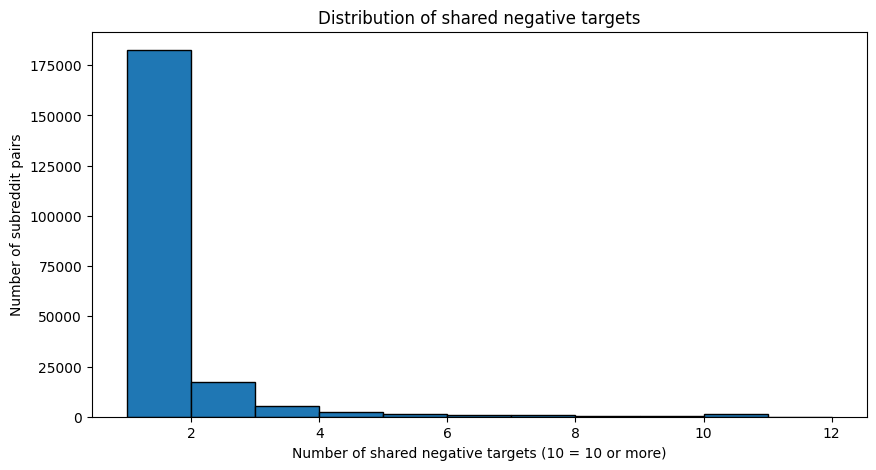

In [27]:
import matplotlib.pyplot as plt

counts = shared_counts["SHARED_NEGATIVE_TARGETS"]

plt.figure(figsize=(10, 5))

plt.hist(
    counts.clip(upper=10),
    bins=range(1, 13),
    edgecolor="black"
)

plt.xlabel("Number of shared negative targets (10 = 10 or more)")
plt.ylabel("Number of subreddit pairs")
plt.title("Distribution of shared negative targets")

plt.show()

LINK_SENTIMENT
 1    265491
-1     21070
Name: count, dtype: int64

Percentages:
LINK_SENTIMENT
 1    92.64729
-1     7.35271
Name: proportion, dtype: float64


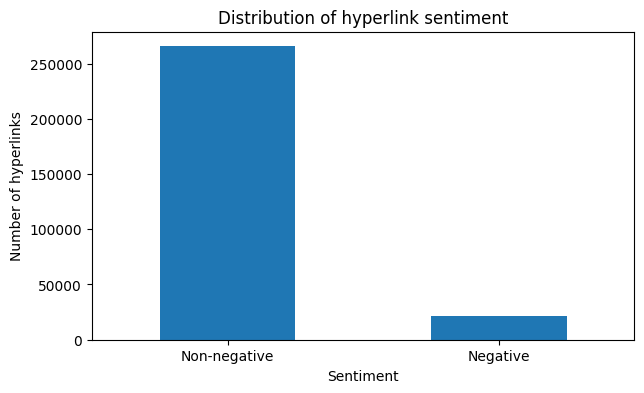

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# Distribution of negative and non-negative links
sentiment_counts = df["LINK_SENTIMENT"].value_counts()

print(sentiment_counts)
print("\nPercentages:")
print(df["LINK_SENTIMENT"].value_counts(normalize=True) * 100)

sentiment_counts.rename({
    -1: "Negative",
     1: "Non-negative"
}).plot(kind="bar", figsize=(7, 4))

plt.title("Distribution of hyperlink sentiment")
plt.ylabel("Number of hyperlinks")
plt.xlabel("Sentiment")
plt.xticks(rotation=0)
plt.show()

TARGET_SUBREDDIT
askreddit         892
worldnews         390
news              390
videos            373
pics              364
todayilearned     362
funny             304
adviceanimals     235
relationships     216
kotakuinaction    200
politics          196
subredditdrama    186
iama              181
the_donald        176
wtf               172
Name: count, dtype: int64

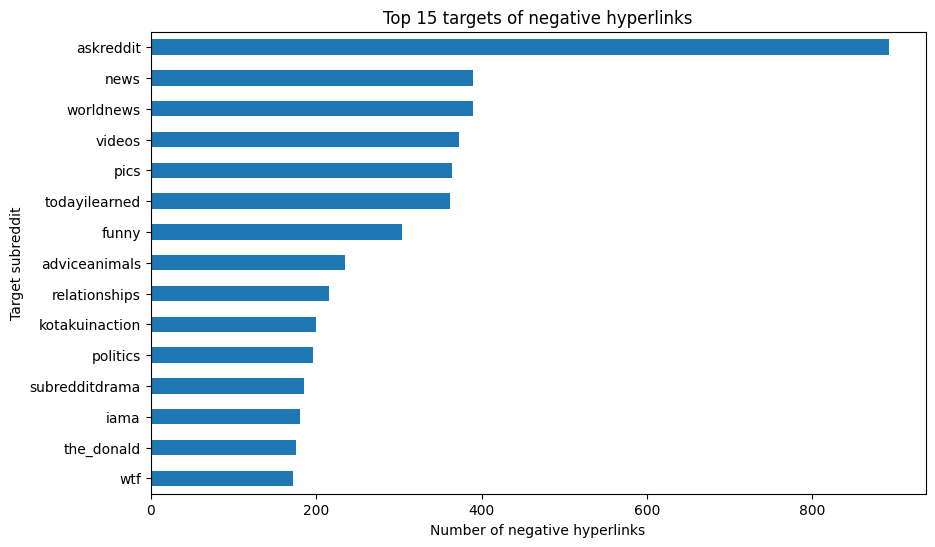

In [29]:
negative_posts = df[df["LINK_SENTIMENT"] == -1].copy()

top_targets = (
    negative_posts["TARGET_SUBREDDIT"]
    .value_counts()
    .head(15)
)

display(top_targets)

top_targets.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 15 targets of negative hyperlinks")
plt.xlabel("Number of negative hyperlinks")
plt.ylabel("Target subreddit")
plt.show()

In [16]:
top_sources = (
    negative_posts["SOURCE_SUBREDDIT"]
    .value_counts()
    .head(15)
)

display(top_sources)

SOURCE_SUBREDDIT
subredditdrama          1437
circlebroke              702
drama                    518
shitliberalssay          407
circlejerkcopypasta      380
copypasta                372
writingprompts           287
conspiracy               281
bestofoutrageculture     229
karmacourt               210
askreddit                199
openbroke                198
subredditcancer          179
shitredditsays           159
badhistory               158
Name: count, dtype: int64

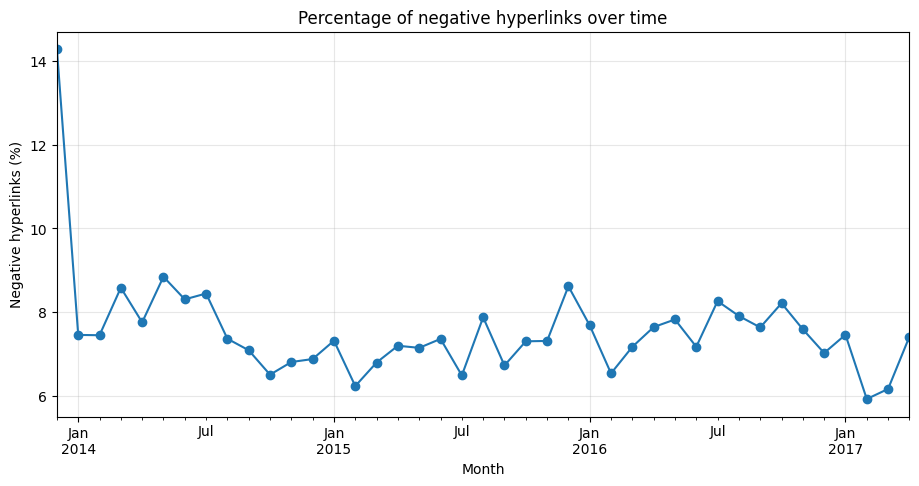

In [19]:
df["TIMESTAMP"] = pd.to_datetime(df["TIMESTAMP"])

df["MONTH"] = df["TIMESTAMP"].dt.to_period("M")

monthly = df.groupby("MONTH").agg(
    total_links=("LINK_SENTIMENT", "size"),
    negative_links=("LINK_SENTIMENT", lambda x: (x == -1).sum())
)

monthly["negative_percentage"] = (
    monthly["negative_links"] / monthly["total_links"] * 100
)

monthly.index = monthly.index.to_timestamp()

monthly["negative_percentage"].plot(
    figsize=(11, 5),
    marker="o"
)

plt.title("Percentage of negative hyperlinks over time")
plt.xlabel("Month")
plt.ylabel("Negative hyperlinks (%)")
plt.grid(alpha=0.3)
plt.show()

Total distinct subreddit pairs: 124330
Pairs with at least 2 links: 33333
Pairs with at least 5 links: 9454
Pairs with at least 10 links: 4140

Percentage with repeated interactions:
26.81 %


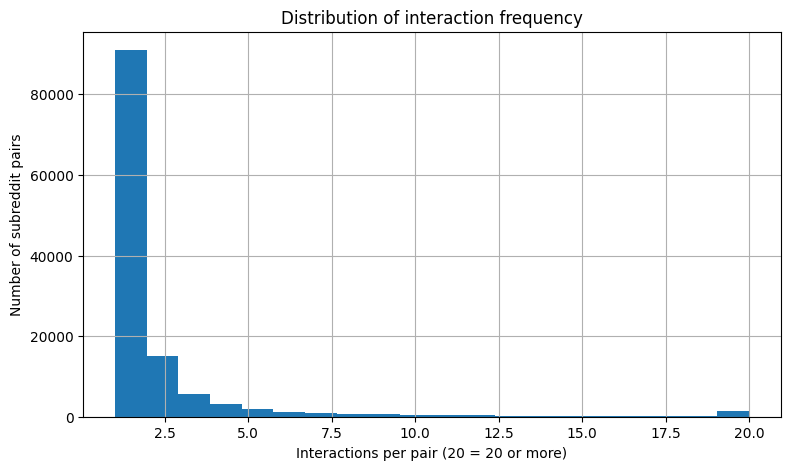

In [21]:
# Count interactions for each unordered pair
pair_df = df.copy()

pair_df["PAIR"] = list(zip(
    pair_df[["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT"]].min(axis=1),
    pair_df[["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT"]].max(axis=1)
))

pair_activity = pair_df.groupby("PAIR").size()

print("Total distinct subreddit pairs:", len(pair_activity))
print("Pairs with at least 2 links:", (pair_activity >= 2).sum())
print("Pairs with at least 5 links:", (pair_activity >= 5).sum())
print("Pairs with at least 10 links:", (pair_activity >= 10).sum())

print("\nPercentage with repeated interactions:")
print(round((pair_activity >= 2).mean() * 100, 2), "%")
pair_activity.clip(upper=20).hist(
    bins=20,
    figsize=(9, 5)
)

plt.xlabel("Interactions per pair (20 = 20 or more)")
plt.ylabel("Number of subreddit pairs")
plt.title("Distribution of interaction frequency")
plt.show()

## Revenge ?

In [23]:
events = df[
    ["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT",
     "TIMESTAMP", "LINK_SENTIMENT"]
].dropna().copy()

events = events.sort_values("TIMESTAMP").reset_index(drop=True)

# Exclude links without a full 30-day follow-up
last_date = events["TIMESTAMP"].max()

initial = events[
    events["TIMESTAMP"] <= last_date - pd.Timedelta(days=30)
].copy()

# Start with negative events
initial = initial[initial["LINK_SENTIMENT"] == -1].copy()
initial["EVENT_ID"] = range(len(initial))

# Find reverse negative links
reverse = events[events["LINK_SENTIMENT"] == -1].copy()

reverse = reverse.rename(columns={
    "SOURCE_SUBREDDIT": "TARGET_SUBREDDIT",
    "TARGET_SUBREDDIT": "SOURCE_SUBREDDIT",
    "TIMESTAMP": "REVERSE_TIME"
})

# Join on opposite directions
matches = initial.merge(
    reverse[
        ["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "REVERSE_TIME"]
    ],
    on=["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT"],
    how="left"
)

# Keep reverse negative links within 30 days
retaliations = matches[
    (matches["REVERSE_TIME"] > matches["TIMESTAMP"]) &
    (matches["REVERSE_TIME"] <=
     matches["TIMESTAMP"] + pd.Timedelta(days=30))
]

n_retaliated = retaliations["EVENT_ID"].nunique()

print("Eligible initial negative events:", len(initial))
print("Events with a subsequent reverse negative link:", n_retaliated)
print("Percentage:", round(n_retaliated / len(initial) * 100, 2), "%")

Eligible initial negative events: 20382
Events with a subsequent reverse negative link: 213
Percentage: 1.05 %
